## Lab Sheet 01
### Sentiment Analysis Using Traditional Machine Learning 


- Import the required Python libraries for data processing, text preprocessing, machine learning, and model evaluation.

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
import os
# Load the datasets and combine them into a single DataFrame for sentiment analysis.
files = {
    "Amazon": "C:/Users/USER/Desktop/UNI/3rd year/day1/amazon_cells_labelled.txt",
    "IMDb": "C:/Users/USER/Desktop/UNI/3rd year/day1/imdb_labelled.txt",
    "Yelp": "C:/Users/USER/Desktop/UNI/3rd year/day1/yelp_labelled.txt"
}

frames = []

for source, file in files.items():
    temp = pd.read_csv(
        file,
        sep="\t",
        header=None,
        names=["sentence", "label"]
    )
    
    temp["source"] = source
    frames.append(temp)

df = pd.concat(frames, ignore_index=True)

print("Dataset shape:", df.shape)
display(df.head())



Dataset shape: (2748, 3)


,sentence,label,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


In [4]:
# Count the number of positive and negative reviews in the dataset.
print("Label counts:")
display(df["label"].value_counts())


Label counts:


label
1    1386
0    1362
Name: count, dtype: int64

### 02. Basic text preprocessing
- Convert text to lowercase.  
- Remove unnecessary characters and punctuation.  
- Remove extra whitespace.  
- Create a clean-text column.  
- Compare original and preprocessed text.

In [5]:
def clean_text(text):
    text = str(text).lower()
    
    # Remove punctuation and unnecessary characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    
    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

In [6]:
#convert text to lowercase

df["clean_text"] = df["sentence"].apply(clean_text)

display(df[["sentence", "clean_text"]].head(10))

,sentence,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


In [7]:
#compare original and preprocessed text

comparison = df[["sentence", "clean_text", "label"]].sample(
    10,
    random_state=42
)

comparison["label"] = comparison["label"].map({
    0: "Negative",
    1: "Positive"
})

display(comparison)

,sentence,clean_text,label
2516,"It's close to my house, it's low-key, non-fanc...",it s close to my house it s low key non fancy ...,Positive
2642,If you stay in Vegas you must get breakfast he...,if you stay in vegas you must get breakfast he...,Positive
1359,"Let's start with all the problemsthe acting, ...",let s start with all the problems the acting e...,Negative
1702,It's too bad that everyone else involved didn'...,it s too bad that everyone else involved didn ...,Negative
2660,"i felt insulted and disrespected, how could yo...",i felt insulted and disrespected how could you...,Negative
564,Yet Plantronincs continues to use the same fla...,yet plantronincs continues to use the same fla...,Negative
1330,Whatever prompted such a documentary is beyond...,whatever prompted such a documentary is beyond me,Negative
2375,Any grandmother can make a roasted chicken bet...,any grandmother can make a roasted chicken bet...,Negative
695,Do NOT buy if you want to use the holster.,do not buy if you want to use the holster,Negative
321,I ordered this product first and was unhappy w...,i ordered this product first and was unhappy w...,Negative


### 03.Explore the text data
-  Display positive and negative examples.  
- Identify frequently occurring words.
- Observe differences between positive and negative reviews. 

In [8]:
#Display positive examples
print("Positive reviews:")

display(
    df[df["label"] == 1][["sentence", "source"]].head(10)
)

Positive reviews:


,sentence,source
1,"Good case, Excellent value.",Amazon
2,Great for the jawbone.,Amazon
4,The mic is great.,Amazon
7,If you are Razr owner...you must have this!,Amazon
10,And the sound quality is great.,Amazon
11,He was very impressed when going from the orig...,Amazon
13,Very good quality though,Amazon
15,Highly recommend for any one who has a blue to...,Amazon
17,So Far So Good!.,Amazon
18,Works great!.,Amazon


In [10]:
#Display negative examples
print("Negative reviews:")

display(
    df[df["label"] == 0][["sentence", "source"]].tail(10)
)

Negative reviews:


,sentence,source
2738,The refried beans that came with my meal were ...,Yelp
2739,Spend your money and time some place else.,Yelp
2740,A lady at the table next to us found a live gr...,Yelp
2741,the presentation of the food was awful.,Yelp
2742,I can't tell you how disappointed I was.,Yelp
2743,I think food should have flavor and texture an...,Yelp
2744,Appetite instantly gone.,Yelp
2745,Overall I was not impressed and would not go b...,Yelp
2746,"The whole experience was underwhelming, and I ...",Yelp
2747,"Then, as if I hadn't wasted enough of my life ...",Yelp


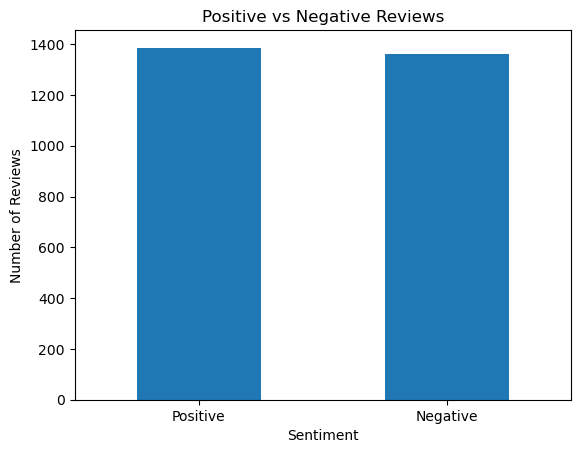

In [11]:
#Compare positive and negative reviews
label_counts = df["label"].map({
    0: "Negative",
    1: "Positive"
}).value_counts()

label_counts.plot(kind="bar")

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

In [13]:
#Identify frequently occurring words
from collections import Counter

def most_common_words(text_series, n=15):
    words = " ".join(text_series).split()
    return Counter(words).most_common(n)


In [14]:
#Positive words
positive_words = most_common_words(
    df[df["label"] == 1]["clean_text"]
)

print("Most common words in positive reviews:")

display(
    pd.DataFrame(
        positive_words,
        columns=["Word", "Count"]
    )
)

Most common words in positive reviews:


,Word,Count
0,the,960
1,and,665
2,i,475
3,a,449
4,is,397
5,it,363
6,this,318
7,to,288
8,of,287
9,was,248


In [15]:
#Negative words
negative_words = most_common_words(
    df[df["label"] == 0]["clean_text"]
)

print("Most common words in negative reviews:")

display(
    pd.DataFrame(
        negative_words,
        columns=["Word", "Count"]
    )
)

Most common words in negative reviews:


,Word,Count
0,the,993
1,i,562
2,and,473
3,a,440
4,it,426
5,to,382
6,is,357
7,of,337
8,this,325
9,was,323


### 04.Split the dataset
          80% → training
          20% → testing

In [16]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2198
Testing samples: 550


### 05.Create Bag of Words representation(BOW)

In [17]:
vectorizer = CountVectorizer(
    stop_words="english",
    min_df=2
)

X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

print("Training BoW shape:", X_train_bow.shape)
print("Testing BoW shape:", X_test_bow.shape)

Training BoW shape: (2198, 1643)
Testing BoW shape: (550, 1643)


In [18]:
print("First 20 vocabulary words:")

print(
    vectorizer.get_feature_names_out()[:20]
)

First 20 vocabulary words:
['10' '100' '11' '12' '15' '20' '2005' '20th' '25' '30' '40' '50' '510'
 '70' '80' '90' 'ability' 'able' 'absolutely' 'accept']


### 06.Train the Machine Learning model
    - Logistic Regression

In [19]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_bow, y_train)

print("Model training completed.")

Model training completed.


In [20]:
# Make predictions
y_pred = model.predict(X_test_bow)

print("Predictions completed.")

Predictions completed.


### 07. Evaluate the model's performance.

In [21]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# F1-score
f1 = f1_score(y_test, y_pred)
print("F1-score:", f1)


Accuracy: 0.7872727272727272
Precision: 0.8076923076923077
Recall: 0.7581227436823105
F1-score: 0.7821229050279329


In [22]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(results)

,Metric,Score
0,Accuracy,0.787273
1,Precision,0.807692
2,Recall,0.758123
3,F1-score,0.782123


In [23]:
# Classification report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.77      0.82      0.79       273
    Positive       0.81      0.76      0.78       277

    accuracy                           0.79       550
   macro avg       0.79      0.79      0.79       550
weighted avg       0.79      0.79      0.79       550



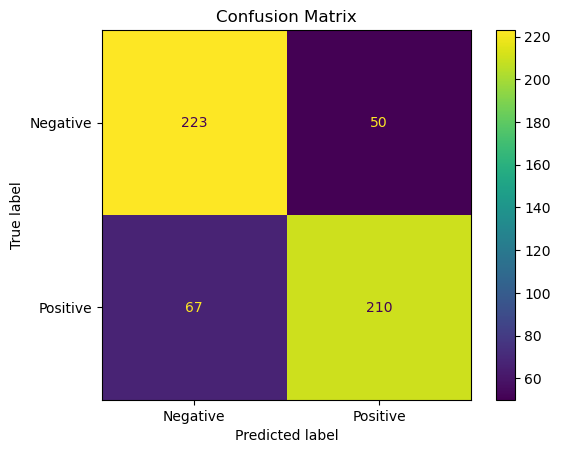

In [24]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

### 08. Test the model with a new sentence

In [25]:
new_sentence = "The product is excellent and I really enjoyed using it."

#Clean it

new_clean = clean_text(new_sentence)

#Convert it into Bag of Words

new_bow = vectorizer.transform([new_clean])

#Predict

prediction = model.predict(new_bow)[0]

if prediction == 1:
    sentiment = "Positive"
else:
    sentiment = "Negative"

print("Sentence:", new_sentence)
print("Predicted sentiment:", sentiment)

Sentence: The product is excellent and I really enjoyed using it.
Predicted sentiment: Positive


In [30]:
new_sentence = "The product is un-worthy."

#Clean it

new_clean = clean_text(new_sentence)

#Convert it into Bag of Words

new_bow = vectorizer.transform([new_clean])

#Predict

prediction = model.predict(new_bow)[0]

if prediction == 1:
    sentiment = "Positive"
else:
    sentiment = "Negative"

print("Sentence:", new_sentence)
print("Predicted sentiment:", sentiment)

Sentence: The product is un-worthy.
Predicted sentiment: Negative
